# Predicting Daily Bike Rental Demand: MLR vs ANN
**DDS2213 Deep Learning and Neural Networks — Coursework 1**
Author: Liang Choong

**Research question:** Between Multiple Linear Regression (MLR) and an Artificial Neural Network (ANN), which approach more accurately predicts total daily bike rentals (`cnt`) using environmental and calendar-related factors?

This notebook follows the **CRISP-DM** process:
1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modelling (MLR, ANN)
5. Evaluation
6. Extension: hourly ANN (beyond the brief)
7. Deployment (Gradio app)

## 0. Setup
Install once if needed: `pip install pandas numpy matplotlib seaborn scikit-learn statsmodels tensorflow gradio`

In [1]:
import os, random, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__)

I0000 00:00:1792750897.255320   16130 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


I0000 00:00:1792750898.655917   16130 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Business Understanding
A bike-sharing company needs accurate daily demand forecasts to allocate bicycles, plan maintenance and schedule staff.
- **Target:** `cnt` (total daily rentals)
- **Task type:** Regression
- **Success metrics:** R² (higher is better), MAE and RMSE (lower is better)

## 2. Data Understanding
Dataset: UCI Bike Sharing Dataset, daily file `day.csv` (Fanaee-T & Gama, 2013). Place `day.csv` in the same folder as this notebook.

In [2]:
df = pd.read_csv("day.csv", parse_dates=["dteday"])
print("Shape:", df.shape)
df.head()

Shape: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

In [4]:
df.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
instant,731.0,366.0,1.0,183.5,366.0,548.5,731.0,211.165812
dteday,731,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731.0,2.49658,1.0,2.0,3.0,3.0,4.0,1.110807
yr,731.0,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
weekday,731.0,2.997264,0.0,1.0,3.0,5.0,6.0,2.004787
workingday,731.0,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,1.395349,1.0,1.0,1.0,2.0,3.0,0.544894
temp,731.0,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate rows: 0


### 2.1 Target distribution

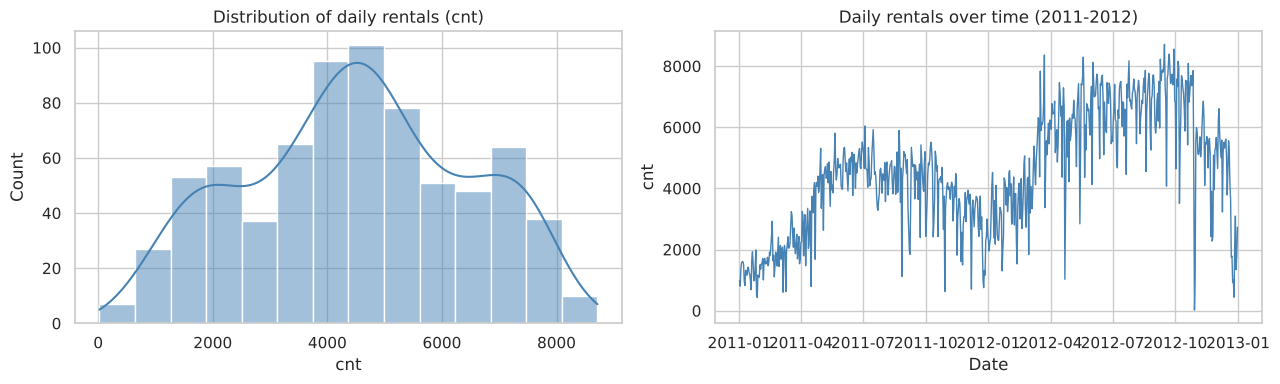

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["cnt"], kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Distribution of daily rentals (cnt)")
ax[1].plot(df["dteday"], df["cnt"], color="steelblue", lw=1)
ax[1].set_title("Daily rentals over time (2011-2012)")
ax[1].set_xlabel("Date"); ax[1].set_ylabel("cnt")
plt.tight_layout(); plt.show()

### 2.2 Rentals by calendar and weather categories
**Note on season labels:** the original dataset readme says 1 = spring ... 4 = winter, but the dates show season 1 runs from 21 Dec to 20 Mar. So the correct labels are 1 = winter, 2 = spring, 3 = summer, 4 = autumn (checked below).

In [7]:
# Dates where the season code changes
df.loc[df["season"] != df["season"].shift(), ["dteday", "season"]]

,dteday,season
0,2011-01-01,1
79,2011-03-21,2
171,2011-06-21,3
265,2011-09-23,4
354,2011-12-21,1
445,2012-03-21,2
537,2012-06-21,3
631,2012-09-23,4
720,2012-12-21,1


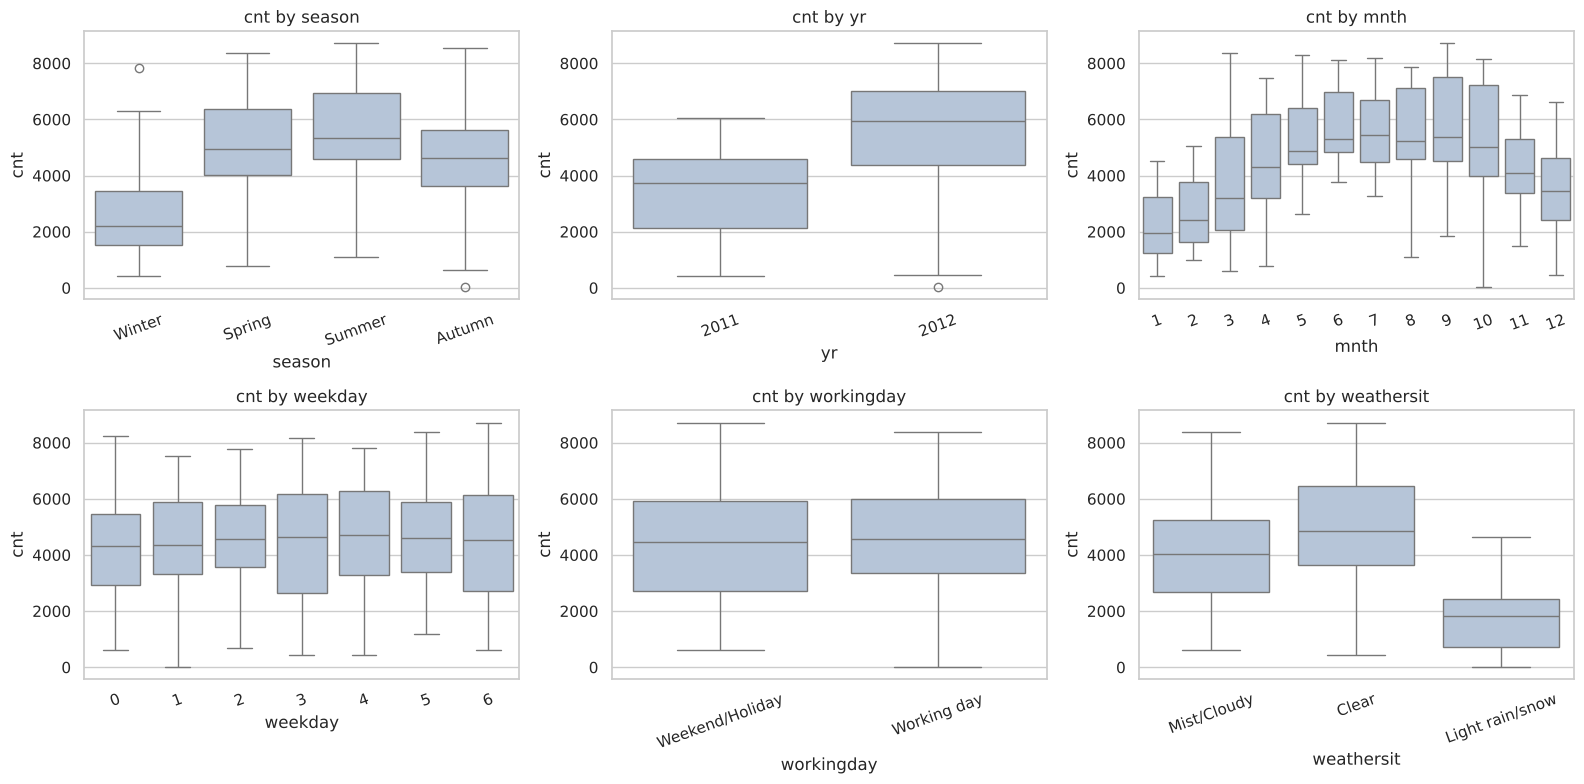

In [8]:
labels = {
    "season": {1: "Winter", 2: "Spring", 3: "Summer", 4: "Autumn"},
    "yr": {0: "2011", 1: "2012"},
    "weathersit": {1: "Clear", 2: "Mist/Cloudy", 3: "Light rain/snow", 4: "Heavy rain"},
    "workingday": {0: "Weekend/Holiday", 1: "Working day"},
}
cats = ["season", "yr", "mnth", "weekday", "workingday", "weathersit"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, cats):
    tmp = df[[c, "cnt"]].copy()
    if c in labels:
        tmp[c] = tmp[c].map(labels[c])
    sns.boxplot(data=tmp, x=c, y="cnt", ax=ax, color="lightsteelblue")
    ax.set_title(f"cnt by {c}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

### 2.3 Numeric weather variables vs rentals

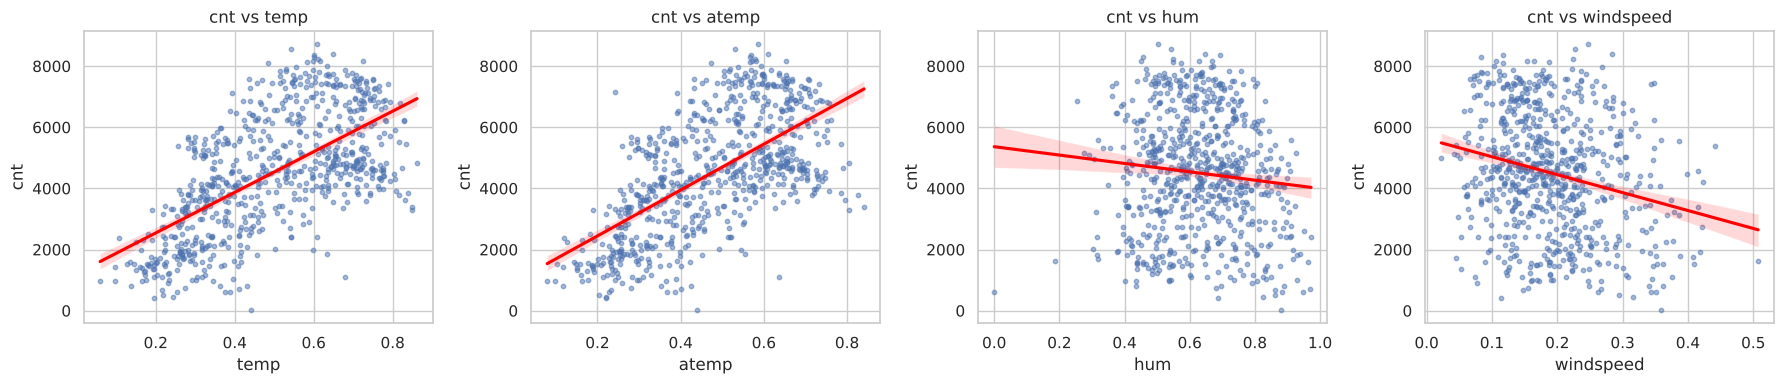

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ["temp", "atemp", "hum", "windspeed"]):
    sns.regplot(data=df, x=c, y="cnt", ax=ax, scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
    ax.set_title(f"cnt vs {c}")
plt.tight_layout(); plt.show()

### 2.4 Correlation heatmap

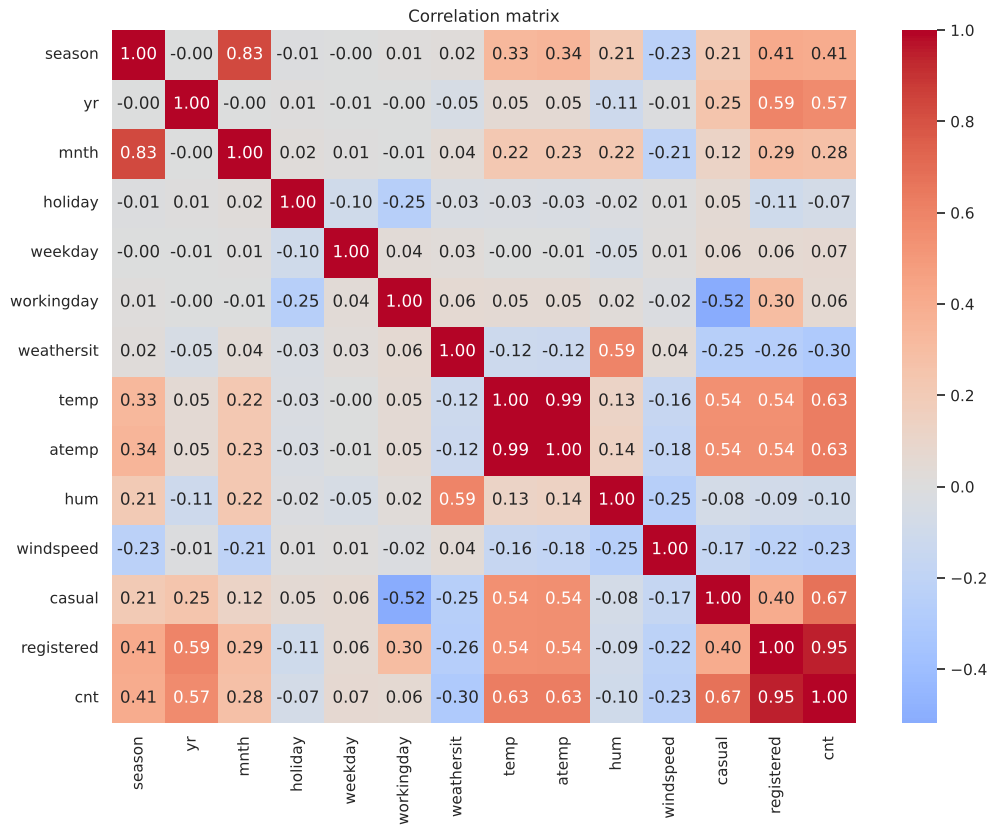

registered    0.946
casual        0.673
atemp         0.631
temp          0.627
yr            0.567
season        0.406
mnth          0.280
weekday       0.067
workingday    0.061
holiday      -0.068
hum          -0.101
windspeed    -0.235
weathersit   -0.297
Name: cnt, dtype: float64


In [10]:
num_cols = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit",
            "temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()
print(df[num_cols].corr()["cnt"].drop("cnt").sort_values(ascending=False).round(3))

**Observations (for the report):**
- `casual + registered = cnt` exactly, so they would leak the answer. They are removed.
- `temp` and `atemp` are almost perfectly correlated (multicollinearity). Only `temp` is kept.
- `instant` (row index) and `dteday` (date) carry no general predictive meaning beyond `yr`/`mnth`/`weekday`, so they are removed.

In [11]:
print("casual + registered == cnt for every row:", (df["casual"] + df["registered"] == df["cnt"]).all())
print("Correlation temp vs atemp:", round(df["temp"].corr(df["atemp"]), 4))

casual + registered == cnt for every row: True
Correlation temp vs atemp: 0.9917


## 3. Data Preparation

### 3.1 Drop leakage / redundant columns

In [12]:
data = df.drop(columns=["instant", "dteday", "casual", "registered", "atemp"])
print(data.columns.tolist())

['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']


### 3.2 One-hot encode categorical variables
`season`, `mnth`, `weekday` and `weathersit` are categories, not quantities, so they are one-hot encoded (`drop_first=True` avoids the dummy-variable trap for MLR).

In [13]:
cat_cols = ["season", "mnth", "weekday", "weathersit"]
data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=int)
X = data.drop(columns=["cnt"])
y = data["cnt"].astype(float)
print("Features:", X.shape[1])
X.head()

Features: 28


,yr,holiday,workingday,temp,hum,windspeed,season_2,season_3,season_4,mnth_2,...,mnth_11,mnth_12,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,weathersit_2,weathersit_3
0,0,0,0,0.344167,0.805833,0.160446,0,0,0,0,...,0,0,0,0,0,0,0,1,1,0
1,0,0,0,0.363478,0.696087,0.248539,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,1,0.196364,0.437273,0.248309,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,0,0,1,0.200000,0.590435,0.160296,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
4,0,0,1,0.226957,0.436957,0.186900,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


### 3.3 Train/test split (80/20) and scaling
The scaler is fitted on the training set only, to avoid information leaking from the test set.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (584, 28)  Test: (147, 28)


## 4. Modelling

### 4.1 Multiple Linear Regression (MLR)
First, an `statsmodels` OLS fit to see which factors are statistically significant (Objective 1).

In [15]:
X_train_const = sm.add_constant(X_train.astype(float))
ols = sm.OLS(y_train, X_train_const).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.839
Method:                 Least Squares   F-statistic:                     113.7
Date:                Fri, 23 Oct 2026   Prob (F-statistic):          1.40e-206
Time:                        18:21:41   Log-Likelihood:                -4694.5
No. Observations:                 584   AIC:                             9445.
Df Residuals:                     556   BIC:                             9567.
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         1343.6165    265.030      5.070   

In [16]:
coef = pd.DataFrame({"coef": ols.params, "p_value": ols.pvalues}).drop("const")
coef["significant (p<0.05)"] = coef["p_value"] < 0.05
coef.sort_values("coef", key=abs, ascending=False).round(4)

,coef,p_value,significant (p<0.05)
temp,4886.0302,0.0000,True
windspeed,-2638.9265,0.0000,True
yr,1980.0594,0.0000,True
weathersit_3,-1839.4828,0.0000,True
season_4,1654.8814,0.0000,True
hum,-1430.2219,0.0000,True
season_2,955.9680,0.0000,True
mnth_9,837.0310,0.0059,True
season_3,816.5188,0.0011,True
mnth_3,581.2147,0.0029,True


Then the scikit-learn MLR used for prediction and comparison (same algorithm, trained on scaled features).

In [17]:
mlr = LinearRegression()
mlr.fit(X_train_s, y_train)
y_pred_mlr = mlr.predict(X_test_s)
print("Intercept:", round(mlr.intercept_, 2))

Intercept:

 4560.98


### 4.2 Artificial Neural Network (ANN)
A feed-forward network (multilayer perceptron) built with Keras. The target is scaled for stable training, then predictions are converted back to rental counts.

In [18]:
y_mean, y_std = y_train.mean(), y_train.std()
y_train_s = (y_train - y_mean) / y_std

def build_ann(hidden=(64, 32), lr=0.001, dropout=0.1, n_inputs=None):
    n_inputs = n_inputs or X_train_s.shape[1]
    model = keras.Sequential([layers.Input(shape=(n_inputs,))])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))  # linear output for regression
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="mse", metrics=["mae"])
    return model

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)

### 4.3 ANN tuning: compare architectures
Each configuration is trained with 20% of the training data held out for validation. The best one is chosen by **validation** RMSE (the test set is not touched).

In [19]:
configs = {
    "A: 32 (1 layer)":        dict(hidden=(32,),         lr=0.001, dropout=0.0),
    "B: 64-32":               dict(hidden=(64, 32),      lr=0.001, dropout=0.1),
    "C: 128-64-32":           dict(hidden=(128, 64, 32), lr=0.001, dropout=0.2),
    "D: 64-32 (lr=0.01)":     dict(hidden=(64, 32),      lr=0.01,  dropout=0.1),
}
X_tr, X_val, y_tr, y_val = train_test_split(X_train_s, y_train_s, test_size=0.2, random_state=SEED)

tuning = []
for name, cfg in configs.items():
    tf.random.set_seed(SEED)
    m = build_ann(**cfg)
    h = m.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=500, batch_size=32,
              callbacks=[early_stop], verbose=0)
    val_pred = m.predict(X_val, verbose=0).ravel() * y_std + y_mean
    val_true = y_val.values * y_std + y_mean
    tuning.append({"Config": name, "Epochs run": len(h.history["loss"]),
                   "Val RMSE": np.sqrt(mean_squared_error(val_true, val_pred)),
                   "Val MAE": mean_absolute_error(val_true, val_pred),
                   "Val R2": r2_score(val_true, val_pred)})
tuning_df = pd.DataFrame(tuning).sort_values("Val RMSE").reset_index(drop=True)
tuning_df.round(3)

,Config,Epochs run,Val RMSE,Val MAE,Val R2
0,D: 64-32 (lr=0.01),39,712.798,498.011,0.829
1,C: 128-64-32,49,727.810,533.399,0.821
2,B: 64-32,135,738.353,511.957,0.816
3,A: 32 (1 layer),88,746.590,558.909,0.812


In [20]:
best_name = tuning_df.loc[0, "Config"]
best_cfg = configs[best_name]
print("Best configuration:", best_name, best_cfg)

Best configuration: D: 64-32 (lr=0.01) {'hidden': (64, 32), 'lr': 0.01, 'dropout': 0.1}


### 4.4 Train the final ANN with the best configuration

In [21]:
tf.random.set_seed(SEED)
ann = build_ann(**best_cfg)
ann.summary()
history = ann.fit(X_train_s, y_train_s, validation_split=0.2, epochs=500, batch_size=32,
                  callbacks=[early_stop], verbose=0)
print("Epochs run:", len(history.history["loss"]))
y_pred_ann = ann.predict(X_test_s, verbose=0).ravel() * y_std + y_mean

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

Epochs run: 47


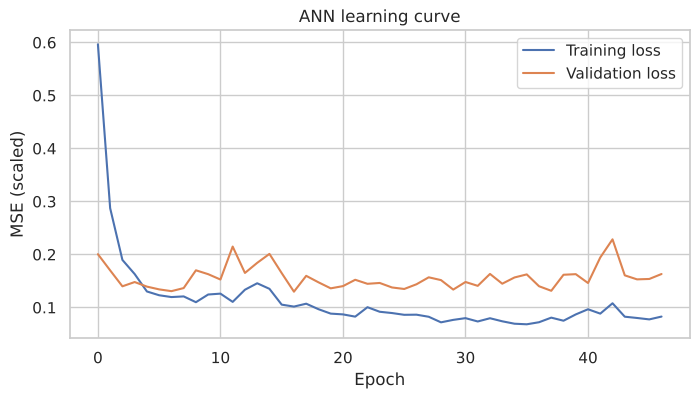

In [22]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE (scaled)")
plt.title("ANN learning curve")
plt.legend(); plt.show()

## 5. Evaluation

### 5.1 Metrics on the test set (Objective 4)
- **R²**: share of variation in rentals explained by the model (higher is better)
- **MAE**: average error in bikes per day (lower is better)
- **RMSE**: like MAE but punishes big misses more (lower is better)
- **WAPE** (extra metric): total error as a % of total rentals (lower is better). Chosen over MAPE because one test day had only 22 rentals (Hurricane Sandy, 29 Oct 2012), which makes MAPE meaningless.

In [23]:
def metrics(y_true, y_pred):
    return {"R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            # Extra metric: WAPE = total absolute error / total actual rentals, as a percentage.
            # Used instead of MAPE because one test day (29 Oct 2012, Hurricane Sandy) had only 22 rentals,
            # which makes MAPE explode. WAPE is the standard % error in demand forecasting.
            "WAPE": np.sum(np.abs(np.asarray(y_true) - y_pred)) / np.sum(np.asarray(y_true)) * 100}

results = pd.DataFrame({"MLR": metrics(y_test, y_pred_mlr),
                        "ANN": metrics(y_test, y_pred_ann)}).T
results.round(4)

,R2,MAE,RMSE,WAPE
MLR,0.8411,584.4505,798.2933,13.6574
ANN,0.8249,582.7140,837.9773,13.6168


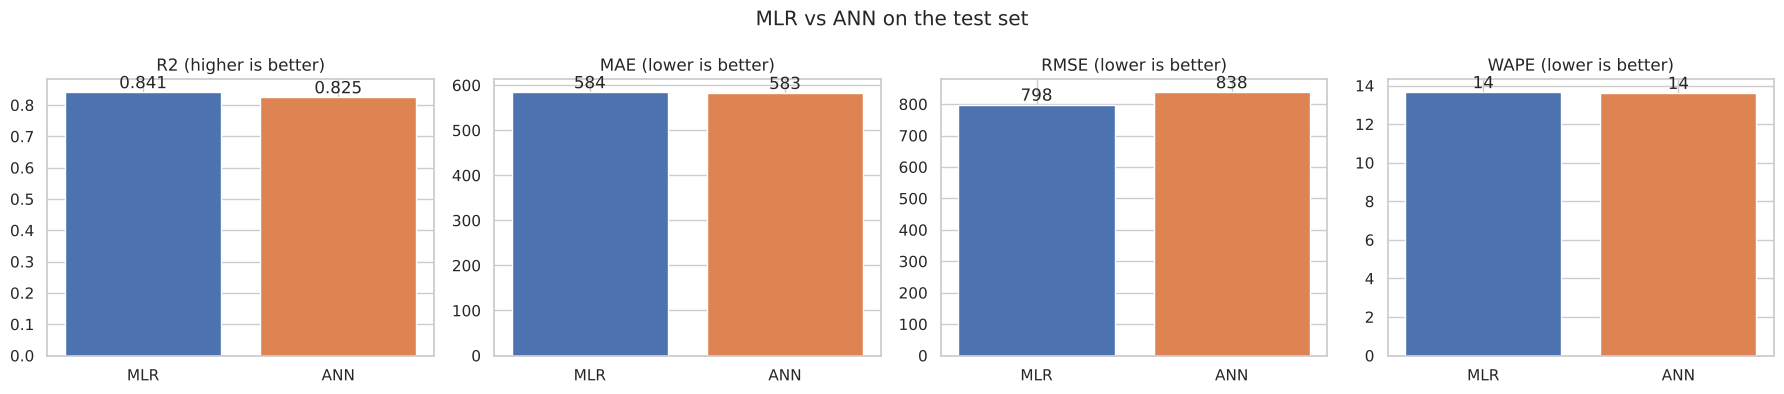

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m in zip(axes, ["R2", "MAE", "RMSE", "WAPE"]):
    bars = ax.bar(results.index, results[m], color=["#4C72B0", "#DD8452"])
    ax.bar_label(bars, fmt="%.3f" if m == "R2" else "%.0f")
    ax.set_title(m + (" (higher is better)" if m == "R2" else " (lower is better)"))
plt.suptitle("MLR vs ANN on the test set"); plt.tight_layout(); plt.show()

### 5.2 Actual vs predicted

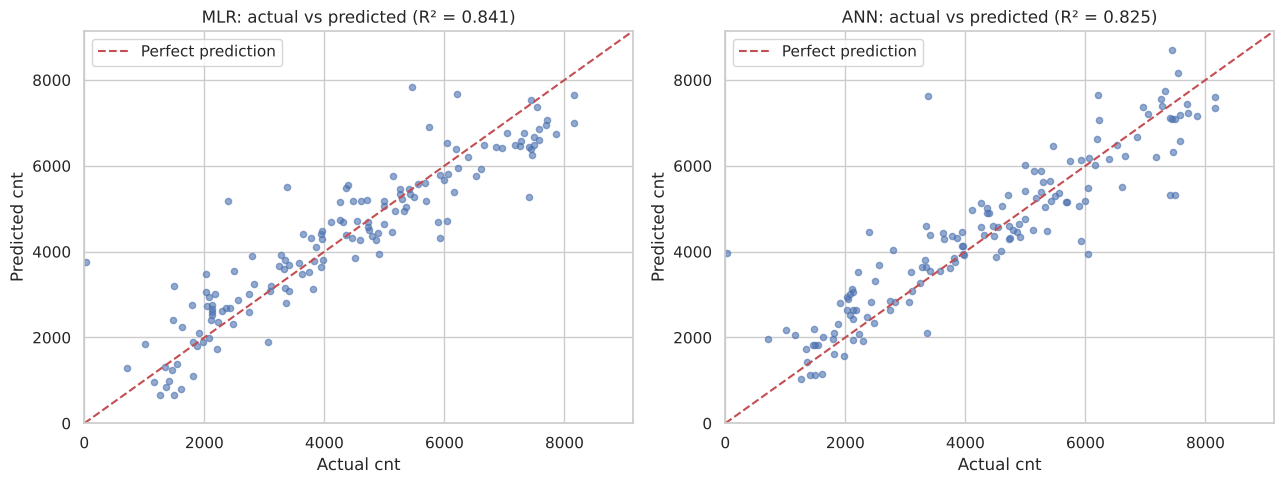

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
lim = [0, max(y_test.max(), y_pred_mlr.max(), y_pred_ann.max()) * 1.05]
for ax, pred, name in zip(axes, [y_pred_mlr, y_pred_ann], ["MLR", "ANN"]):
    ax.scatter(y_test, pred, alpha=0.6, s=20)
    ax.plot(lim, lim, "r--", label="Perfect prediction")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("Actual cnt"); ax.set_ylabel("Predicted cnt")
    ax.set_title(f"{name}: actual vs predicted (R² = {r2_score(y_test, pred):.3f})")
    ax.legend()
plt.tight_layout(); plt.show()

### 5.3 Residual analysis

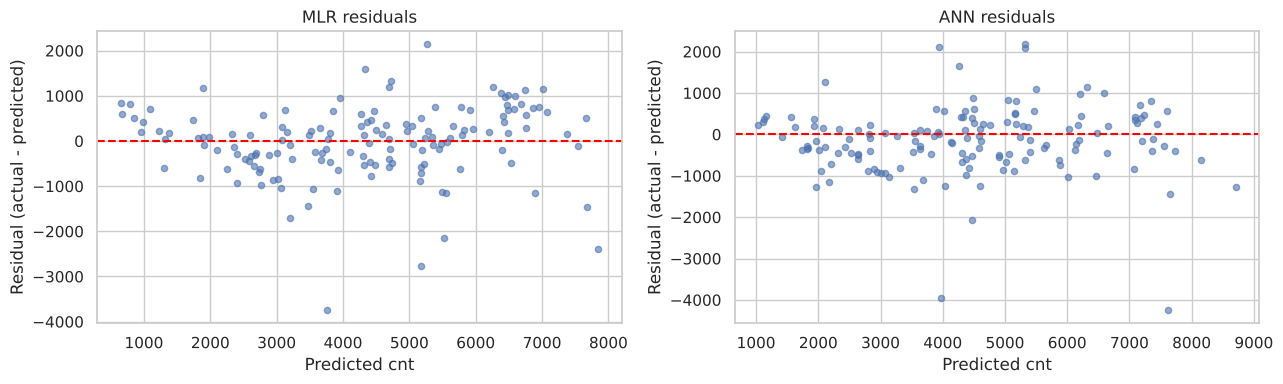

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, pred, name in zip(axes, [y_pred_mlr, y_pred_ann], ["MLR", "ANN"]):
    res = y_test - pred
    ax.scatter(pred, res, alpha=0.6, s=20)
    ax.axhline(0, color="red", ls="--")
    ax.set_xlabel("Predicted cnt"); ax.set_ylabel("Residual (actual - predicted)")
    ax.set_title(f"{name} residuals")
plt.tight_layout(); plt.show()

### 5.4 Robustness check: 5-fold cross-validation
One train/test split can be lucky or unlucky. 5-fold CV gives a fairer comparison.

In [27]:
from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for fold, (tr, te) in enumerate(kf.split(X), 1):
    sc = StandardScaler().fit(X.iloc[tr])
    Xtr, Xte = sc.transform(X.iloc[tr]), sc.transform(X.iloc[te])
    ytr, yte = y.iloc[tr], y.iloc[te]
    p_mlr = LinearRegression().fit(Xtr, ytr).predict(Xte)
    mu, sd = ytr.mean(), ytr.std()
    tf.random.set_seed(SEED)
    m = build_ann(**best_cfg)
    m.fit(Xtr, (ytr - mu) / sd, validation_split=0.2, epochs=500, batch_size=32, callbacks=[early_stop], verbose=0)
    p_ann = m.predict(Xte, verbose=0).ravel() * sd + mu
    for name, p in [("MLR", p_mlr), ("ANN", p_ann)]:
        cv_rows.append({"Fold": fold, "Model": name, **metrics(yte, p)})
cv = pd.DataFrame(cv_rows)
cv_summary = cv.groupby("Model")[["R2", "MAE", "RMSE", "WAPE"]].agg(["mean", "std"]).round(3)
cv_summary

R2             MAE             RMSE            WAPE       
        mean    std     mean     std     mean     std    mean    std
Model                                                               
ANN    0.809  0.049  599.331  79.624  830.848  91.621  13.305  1.696
MLR    0.824  0.038  586.743  16.958  800.136  48.717  13.054  0.775

In [28]:
# Is the difference real or just luck? Paired t-test on the 5 fold RMSEs.
from scipy.stats import ttest_rel
piv = cv.pivot(index="Fold", columns="Model", values="RMSE")
t_stat, p_val = ttest_rel(piv["MLR"], piv["ANN"])
print(f"Paired t-test MLR vs ANN: t = {t_stat:.3f}, p = {p_val:.4f}")
print("Significant at 5%:", p_val < 0.05)

Paired t-test MLR vs ANN: t = -0.687, p = 0.5297
Significant at 5%: False


### 5.5 Which factors matter most? (Objective 1)

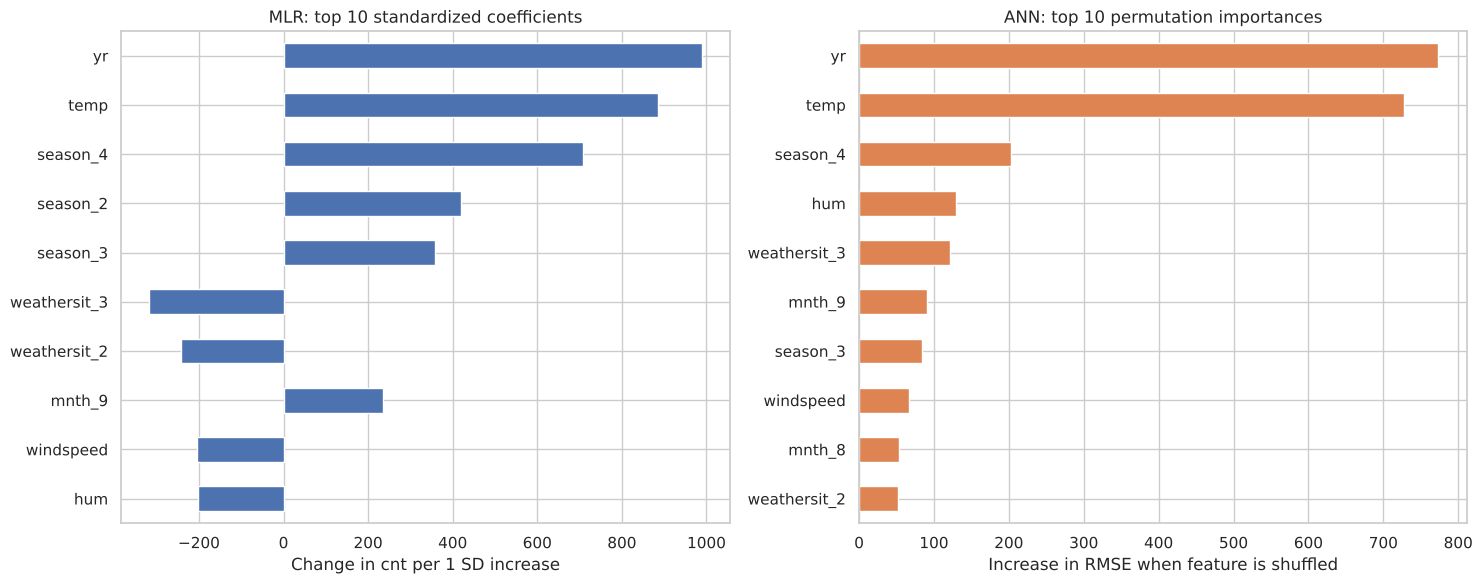

In [29]:
mlr_imp = pd.Series(mlr.coef_, index=X.columns).sort_values(key=abs, ascending=False)
# Permutation importance for the ANN: shuffle one feature at a time and see how much RMSE gets worse
rng = np.random.default_rng(SEED)
base_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ann))
imp = {}
for i, col in enumerate(X.columns):
    scores = []
    for _ in range(10):
        Xp = X_test_s.copy()
        Xp[:, i] = rng.permutation(Xp[:, i])
        p = ann.predict(Xp, verbose=0).ravel() * y_std + y_mean
        scores.append(np.sqrt(mean_squared_error(y_test, p)) - base_rmse)
    imp[col] = np.mean(scores)
ann_imp = pd.Series(imp).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
mlr_imp.head(10).iloc[::-1].plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("MLR: top 10 standardized coefficients")
axes[0].set_xlabel("Change in cnt per 1 SD increase")
ann_imp.head(10).iloc[::-1].plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("ANN: top 10 permutation importances")
axes[1].set_xlabel("Increase in RMSE when feature is shuffled")
plt.tight_layout(); plt.show()

### 5.6 Conclusion

In [30]:
winner = results["RMSE"].idxmin()
loser = "MLR" if winner == "ANN" else "ANN"
print(f"Best model on the test set: {winner}")
print(f"  R2   {results.loc[winner,'R2']:.4f} vs {results.loc[loser,'R2']:.4f}")
print(f"  MAE  {results.loc[winner,'MAE']:.1f} vs {results.loc[loser,'MAE']:.1f}")
print(f"  RMSE {results.loc[winner,'RMSE']:.1f} vs {results.loc[loser,'RMSE']:.1f}")
print("\n5-fold CV mean RMSE:")
print(cv.groupby("Model")["RMSE"].mean().round(1))

Best model on the test set: MLR
  R2   0.8411 vs 0.8249
  MAE  584.5 vs 582.7
  RMSE 798.3 vs 838.0

5-fold CV mean RMSE:
Model
ANN    830.8
MLR    800.1
Name: RMSE, dtype: float64


## 6. Extension: does richer data let the ANN win?
**Going beyond the given project.** The daily dataset has only 731 rows, which is small for a neural network. The same source also provides **hourly** data (17,379 rows). Hourly rentals summed per day equal the daily `cnt` exactly, so an hourly model can still answer the original question: *predict total daily rentals*.

Approach: train MLR and ANN on hourly data, add up the 24 hourly predictions for each day, and compare against the daily models **on exactly the same 147 test days**.

In [31]:
h = pd.read_csv("hour.csv", parse_dates=["dteday"])
print("Hourly shape:", h.shape)
print("Hourly sums equal daily cnt:", (h.groupby("dteday")["cnt"].sum().values == df["cnt"].values).all())

Hourly shape: (17379, 17)
Hourly sums equal daily cnt: True


### 6.1 Data understanding: the hourly pattern

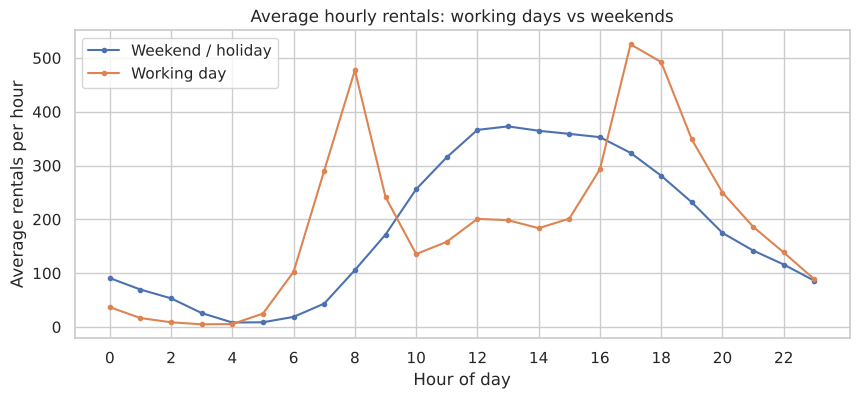

In [32]:
prof = h.groupby(["workingday", "hr"])["cnt"].mean().unstack(0)
prof.columns = ["Weekend / holiday", "Working day"]
ax = prof.plot(figsize=(10, 4), marker="o", ms=3)
ax.set_xlabel("Hour of day"); ax.set_ylabel("Average rentals per hour")
ax.set_title("Average hourly rentals: working days vs weekends")
ax.set_xticks(range(0, 24, 2)); plt.show()

**Observation:** working days have two commute peaks (8am and 5-6pm). Weekends have one broad afternoon peak. The effect of `hr` *depends on* `workingday`. This is an **interaction**, which a plain MLR (adding up separate effects) cannot represent, but an ANN can learn it automatically.

### 6.2 Data preparation
- Same columns removed as before (`casual`, `registered`, `atemp`, `instant`).
- `hr` is one-hot encoded as well.
- **Split by day, not by row:** all 24 hours of a test day stay in the test set. A random row split would leak information, because neighbouring hours of the same day are very similar.
- Hourly rows are stored in date order, so the training rows are **shuffled** before the ANN holds out its 20% validation set. Otherwise the validation set would be only the last weeks of the training period.

In [33]:
train_dates = set(df.loc[X_train.index, "dteday"])
test_dates = df.loc[X_test.index, "dteday"]          # same 147 test days as the daily models

H = pd.get_dummies(h.drop(columns=["instant", "casual", "registered", "atemp"]),
                   columns=cat_cols + ["hr"], drop_first=True, dtype=int)
Xh = H.drop(columns=["dteday", "cnt"])
yh = H["cnt"].astype(float)
tr_mask = H["dteday"].isin(train_dates)
te_mask = H["dteday"].isin(set(test_dates))
scaler_h = StandardScaler().fit(Xh[tr_mask])
Xh_tr, Xh_te = scaler_h.transform(Xh[tr_mask]), scaler_h.transform(Xh[te_mask])
yh_tr, yh_te = yh[tr_mask], yh[te_mask]
print("Hourly train rows:", Xh_tr.shape, " test rows:", Xh_te.shape, " features:", Xh.shape[1])

Hourly train rows: (13893, 52)  test rows: (3486, 52)  features: 52


### 6.3 Modelling: hourly MLR and hourly ANN

In [34]:
mlr_h = LinearRegression().fit(Xh_tr, yh_tr)
p_h_mlr = mlr_h.predict(Xh_te)

early_stop_h = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)

def fit_hourly_ann(Xtr, ytr_raw, seed=SEED):
    yv = np.asarray(ytr_raw, dtype=float)
    mu, sd = yv.mean(), yv.std()
    order = np.random.default_rng(seed).permutation(len(yv))   # shuffle: rows are in date order
    tf.random.set_seed(seed)
    m = build_ann(hidden=(128, 64), lr=0.001, dropout=0.1, n_inputs=Xtr.shape[1])
    hist = m.fit(Xtr[order], ((yv - mu) / sd)[order], validation_split=0.2, epochs=200, batch_size=64,
                 callbacks=[early_stop_h], verbose=0)
    return m, mu, sd, hist

ann_h, h_mu, h_sd, hist_h = fit_hourly_ann(Xh_tr, yh_tr)
p_h_ann = np.clip(ann_h.predict(Xh_te, verbose=0).ravel() * h_sd + h_mu, 0, None)
print("Hourly ANN epochs:", len(hist_h.history["loss"]))

hourly_results = pd.DataFrame({
    "Hourly MLR": {"R2": r2_score(yh_te, p_h_mlr), "MAE": mean_absolute_error(yh_te, p_h_mlr),
                   "RMSE": np.sqrt(mean_squared_error(yh_te, p_h_mlr))},
    "Hourly ANN": {"R2": r2_score(yh_te, p_h_ann), "MAE": mean_absolute_error(yh_te, p_h_ann),
                   "RMSE": np.sqrt(mean_squared_error(yh_te, p_h_ann))}}).T
hourly_results.round(3)

Hourly ANN epochs: 53


,R2,MAE,RMSE
Hourly MLR,0.693,72.680,97.784
Hourly ANN,0.936,27.823,44.532


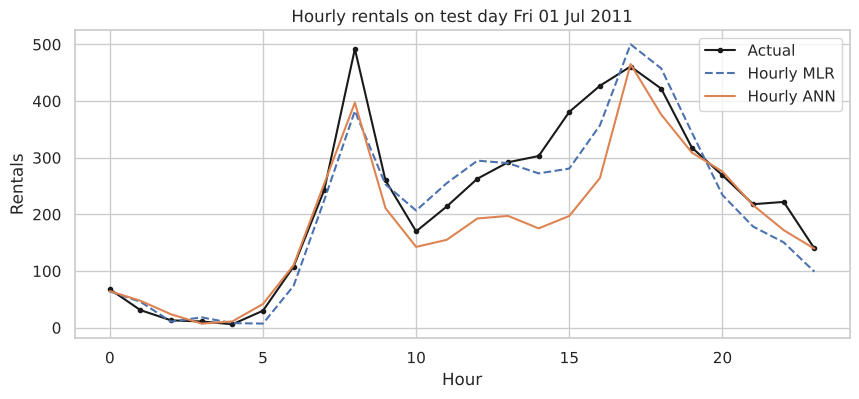

In [35]:
# One example test day: actual vs predicted hourly curve
ex_day = sorted(test_dates)[40]
sel = (H.loc[te_mask, "dteday"] == ex_day).values
plt.figure(figsize=(10, 4))
plt.plot(range(24), yh_te[sel].values, "k-o", ms=3, label="Actual")
plt.plot(range(24), p_h_mlr[sel], "--", label="Hourly MLR")
plt.plot(range(24), p_h_ann[sel], "-", label="Hourly ANN")
plt.title(f"Hourly rentals on test day {ex_day:%a %d %b %Y}")
plt.xlabel("Hour"); plt.ylabel("Rentals"); plt.legend(); plt.show()

### 6.4 Evaluation: all four approaches on the same 147 test days (daily totals)

In [36]:
def to_daily(pred):
    s = pd.DataFrame({"d": H.loc[te_mask, "dteday"].values, "p": pred}).groupby("d")["p"].sum()
    return s.reindex(test_dates).values

y_pred_hmlr_day = to_daily(p_h_mlr)
y_pred_hann_day = to_daily(p_h_ann)
final = pd.DataFrame({
    "Daily MLR": metrics(y_test, y_pred_mlr),
    "Daily ANN": metrics(y_test, y_pred_ann),
    "Hourly MLR -> daily": metrics(y_test, y_pred_hmlr_day),
    "Hourly ANN -> daily": metrics(y_test, y_pred_hann_day)}).T
final.round(3)

,R2,MAE,RMSE,WAPE
Daily MLR,0.841,584.450,798.293,13.657
Daily ANN,0.825,582.714,837.977,13.617
Hourly MLR -> daily,0.868,552.457,727.189,12.910
Hourly ANN -> daily,0.936,366.246,505.228,8.558


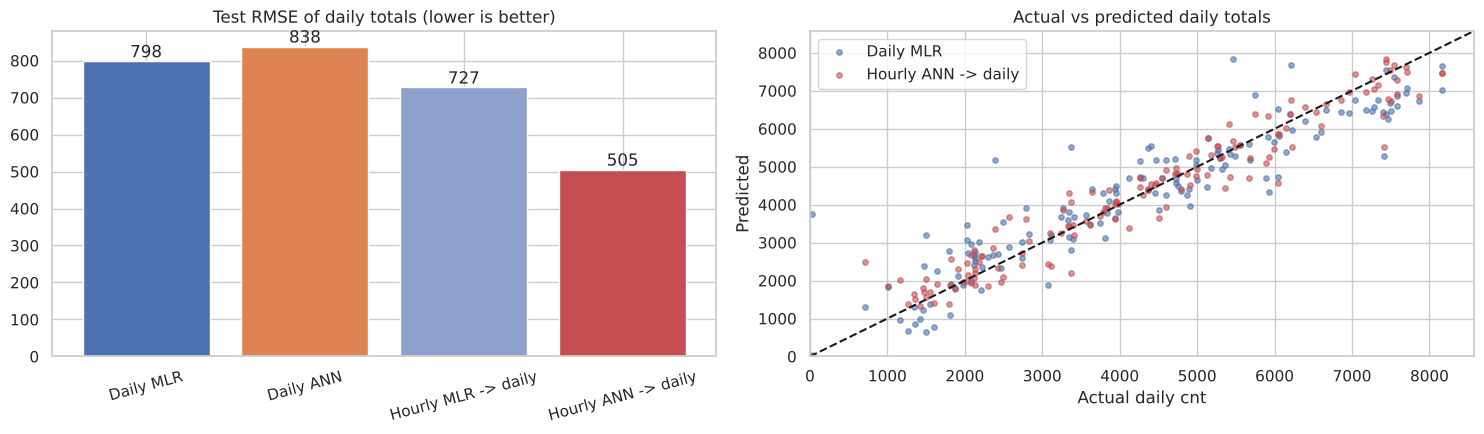

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
colors = ["#4C72B0", "#DD8452", "#8DA0CB", "#C44E52"]
bars = axes[0].bar(final.index, final["RMSE"], color=colors)
axes[0].bar_label(bars, fmt="%.0f"); axes[0].set_title("Test RMSE of daily totals (lower is better)")
axes[0].tick_params(axis="x", rotation=15)
lim = [0, y_test.max() * 1.05]
axes[1].scatter(y_test, y_pred_mlr, s=15, alpha=0.6, label="Daily MLR")
axes[1].scatter(y_test, y_pred_hann_day, s=15, alpha=0.6, color="#C44E52", label="Hourly ANN -> daily")
axes[1].plot(lim, lim, "k--"); axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("Actual daily cnt"); axes[1].set_ylabel("Predicted"); axes[1].legend()
axes[1].set_title("Actual vs predicted daily totals")
plt.tight_layout(); plt.show()

### 6.5 Robustness: 5-fold cross-validation for all four approaches
Same day-based folds as Section 5.4. Hourly models are trained only on the hours of the training days.

In [38]:
ext_rows = []
for fold, (tr, te) in enumerate(kf.split(X), 1):
    tr_d, te_d = set(df.loc[tr, "dteday"]), df.loc[te, "dteday"]
    m_tr, m_te = H["dteday"].isin(tr_d), H["dteday"].isin(set(te_d))
    sc = StandardScaler().fit(Xh[m_tr])
    a, b = sc.transform(Xh[m_tr]), sc.transform(Xh[m_te])
    days_te = H.loc[m_te, "dteday"].values
    agg = lambda p: pd.DataFrame({"d": days_te, "p": p}).groupby("d")["p"].sum().reindex(te_d).values
    p1 = LinearRegression().fit(a, yh[m_tr]).predict(b)
    m, mu, sd, _ = fit_hourly_ann(a, yh[m_tr])
    p2 = np.clip(m.predict(b, verbose=0).ravel() * sd + mu, 0, None)
    yte = df.loc[te, "cnt"].values
    ext_rows.append({"Fold": fold, "Model": "Hourly MLR -> daily", **metrics(yte, agg(p1))})
    ext_rows.append({"Fold": fold, "Model": "Hourly ANN -> daily", **metrics(yte, agg(p2))})

cv_all = pd.concat([cv.replace({"Model": {"MLR": "Daily MLR", "ANN": "Daily ANN"}}), pd.DataFrame(ext_rows)])
cv_all_summary = cv_all.groupby("Model")[["R2", "MAE", "RMSE", "WAPE"]].agg(["mean", "std"]).round(3)
cv_all_summary.sort_values(("RMSE", "mean"))

R2             MAE              RMSE             WAPE  \
                      mean    std     mean      std     mean      std    mean   
Model                                                                           
Hourly ANN -> daily  0.899  0.051  443.022  110.074  594.262  146.572   9.826   
Hourly MLR -> daily  0.840  0.042  566.634   13.858  759.688   54.249  12.598   
Daily MLR            0.824  0.038  586.743   16.958  800.136   48.717  13.054   
Daily ANN            0.809  0.049  599.331   79.624  830.848   91.621  13.305   

                            
                       std  
Model                       
Hourly ANN -> daily  2.343  
Hourly MLR -> daily  0.490  
Daily MLR            0.775  
Daily ANN            1.696

In [39]:
from scipy.stats import ttest_rel
piv_all = cv_all.pivot(index="Fold", columns="Model", values="RMSE")
t_h, p_ttest_h = ttest_rel(piv_all["Daily MLR"], piv_all["Hourly ANN -> daily"])
print(f"Paired t-test, Daily MLR vs Hourly ANN (RMSE over 5 folds): t = {t_h:.3f}, p = {p_ttest_h:.4f}")
print("Significant at 5%:", p_ttest_h < 0.05)

Paired t-test, Daily MLR vs Hourly ANN (RMSE over 5 folds): t = 2.609, p = 0.0595
Significant at 5%: False


### 6.6 Learning curve: how much data does the ANN need?
Train the hourly models on a growing number of training days and test on the same 147 test days.

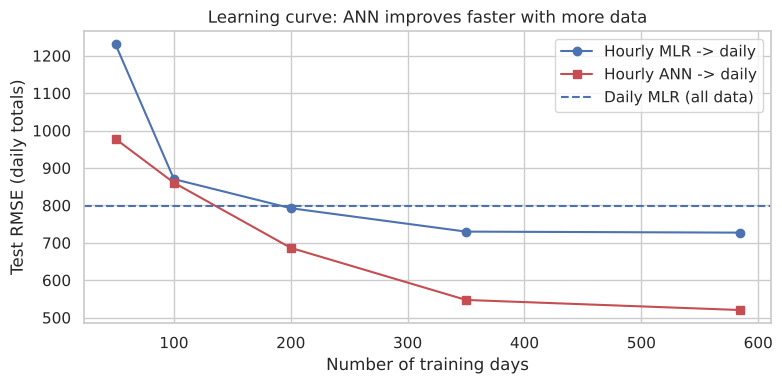

,Training days,Hourly rows,Hourly MLR -> daily,Hourly ANN -> daily
0,50,1194,1230.7,977.8
1,100,2383,870.3,860.6
2,200,4770,792.4,686.4
3,350,8321,729.9,547.2
4,584,13893,727.2,520.3


In [40]:
rng_lc = np.random.default_rng(SEED)
train_days_list = sorted(train_dates)
sizes = [50, 100, 200, 350, len(train_days_list)]
lc = []
for n in sizes:
    days = set(rng_lc.choice(train_days_list, size=n, replace=False))
    m_tr = H["dteday"].isin(days)
    sc = StandardScaler().fit(Xh[m_tr])
    a = sc.transform(Xh[m_tr]); b = sc.transform(Xh[te_mask])
    p1 = LinearRegression().fit(a, yh[m_tr]).predict(b)
    m, mu, sd, _ = fit_hourly_ann(a, yh[m_tr])
    p2 = np.clip(m.predict(b, verbose=0).ravel() * sd + mu, 0, None)
    lc.append({"Training days": n, "Hourly rows": int(m_tr.sum()),
               "Hourly MLR -> daily": np.sqrt(mean_squared_error(y_test, to_daily(p1))),
               "Hourly ANN -> daily": np.sqrt(mean_squared_error(y_test, to_daily(p2)))})
lc = pd.DataFrame(lc)

lc_fig = plt.figure(figsize=(8, 4))
plt.plot(lc["Training days"], lc["Hourly MLR -> daily"], "o-", label="Hourly MLR -> daily")
plt.plot(lc["Training days"], lc["Hourly ANN -> daily"], "s-", color="#C44E52", label="Hourly ANN -> daily")
plt.axhline(final.loc["Daily MLR", "RMSE"], ls="--", color="#4C72B0", label="Daily MLR (all data)")
plt.xlabel("Number of training days"); plt.ylabel("Test RMSE (daily totals)")
plt.title("Learning curve: ANN improves faster with more data"); plt.legend()
plt.tight_layout(); plt.show()
lc.round(1)

### 6.7 Conclusion

In [41]:
best_cv = cv_all.groupby("Model")["RMSE"].mean().sort_values()
print("Mean 5-fold CV RMSE (daily totals):")
print(best_cv.round(1))
print(f"\nBest overall: {best_cv.index[0]}")
print(f"On the small daily dataset, {'MLR' if results.loc['MLR','RMSE'] < results.loc['ANN','RMSE'] else 'ANN'} wins (test RMSE "
      f"{results.loc['MLR','RMSE']:.0f} vs {results.loc['ANN','RMSE']:.0f}).")
print(f"With hourly data the ANN reduces daily RMSE from {final.loc['Daily MLR','RMSE']:.0f} to "
      f"{final.loc['Hourly ANN -> daily','RMSE']:.0f} "
      f"({(1 - final.loc['Hourly ANN -> daily','RMSE'] / final.loc['Daily MLR','RMSE']) * 100:.0f}% lower).")

Mean 5-fold CV RMSE (daily totals):
Model
Hourly ANN -> daily    594.3
Hourly MLR -> daily    759.7
Daily MLR              800.1
Daily ANN              830.8
Name: RMSE, dtype: float64

Best overall: Hourly ANN -> daily
On the small daily dataset, MLR wins (test RMSE 798 vs 838).
With hourly data the ANN reduces daily RMSE from 798 to 505 (37% lower).


## 7. Deployment
Save the trained models and the metadata the app needs. Then run the app from a terminal:

`python app.py`

The app (`app.py` + `predictor.py`) loads these files, validates every input, applies business rules, and turns the forecast into an operations plan with an hourly demand profile.

In [42]:
import json, joblib
os.makedirs("models", exist_ok=True)
ann.save("models/ann_model.keras")
joblib.dump({"scaler": scaler, "mlr": mlr, "columns": X.columns.tolist(),
             "y_mean": float(y_mean), "y_std": float(y_std)}, "models/preprocess_mlr.joblib")
ann_h.save("models/ann_hourly.keras")
joblib.dump({"scaler": scaler_h, "columns": Xh.columns.tolist(),
             "y_mu": float(h_mu), "y_sd": float(h_sd)}, "models/preprocess_hourly.joblib")
lc_fig.savefig("models/learning_curve.png", dpi=120)

name_map = {"Daily MLR": "MLR", "Daily ANN": "ANN", "Hourly ANN -> daily": "Hourly ANN"}
cv_m = cv_all.groupby("Model")["RMSE"].agg(["mean", "std"])
served = cv_m.loc[list(name_map)]                       # models the app can serve
meta = {
    "best_model": name_map[served["mean"].idxmin()],   # chosen by 5-fold CV RMSE
    "ann_config": best_name,
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "test_metrics": {name_map.get(k, k): {m: float(v) for m, v in final.loc[k].items()} for k in final.index},
    "cv_metrics": {name_map.get(k, k): {"RMSE_mean": float(cv_m.loc[k, "mean"]), "RMSE_std": float(cv_m.loc[k, "std"])}
                   for k in cv_m.index},
    "ttest_daily_mlr_vs_hourly_ann_p": float(p_ttest_h),
    "ttest_daily_mlr_vs_daily_ann_p": float(p_val),
    "hourly_test_metrics": {k: {m: float(v) for m, v in hourly_results.loc[k].items()} for k in hourly_results.index},
    "cnt_q33": float(df["cnt"].quantile(0.33)), "cnt_q66": float(df["cnt"].quantile(0.66)),
    "cnt_max": float(df["cnt"].max()),
    "training_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in ["temp", "hum", "windspeed"]},
}
with open("models/metrics.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2)
print(json.dumps(meta, indent=2))

{
  "best_model": "Hourly ANN",
  "ann_config": "D: 64-32 (lr=0.01)",
  "n_train": 584,
  "n_test": 147,
  "test_metrics": {
    "MLR": {
      "R2": 0.8410745782487739,
      "MAE": 584.4504682073664,
      "RMSE": 798.293325717996,
      "WAPE": 13.657381845282682
    },
    "ANN": {
      "R2": 0.8248811471186004,
      "MAE": 582.7140251866181,
      "RMSE": 837.977318646619,
      "WAPE": 13.616804813220964
    },
    "Hourly MLR -> daily": {
      "R2": 0.8681249329660413,
      "MAE": 552.4565220531179,
      "RMSE": 727.1887620179698,
      "WAPE": 12.909750415186963
    },
    "Hourly ANN": {
      "R2": 0.9363434227425103,
      "MAE": 366.2457895590219,
      "RMSE": 505.2280491982339,
      "WAPE": 8.55839608200961
    }
  },
  "cv_metrics": {
    "ANN": {
      "RMSE_mean": 830.84771223103,
      "RMSE_std": 91.62085308919158
    },
    "MLR": {
      "RMSE_mean": 800.1360981926808,
      "RMSE_std": 48.71693766084899
    },
    "Hourly ANN": {
      "RMSE_mean": 594.26171